# Predicting Commuting Time in South Africa

## 1. Data Loading and Initial Exploration

In [17]:
# Importing libraries for data manipulation, ZIP file handling, and file paths
import pandas as pd
import zipfile
from pathlib import Path

In [18]:
# Defining the path to the compressed survey dataset
dataset_path = Path("../data/nhts-2020-v1.zip")

# Opening the ZIP file and loading the Stata person-level dataset
with zipfile.ZipFile(dataset_path) as z:
    with z.open("nhts-2020-v1/nhts-2020-v1-stata/nhts-2020-person.dta") as f:
        df = pd.read_stata(f, convert_categoricals=False)

# Checking the number of rows and columns in the dataset
print(df.shape)

(145385, 274)


In [19]:
#Selecting eight independent variables

features= [
    "Age",
    "Sex",
    "Q43SectOfWork",
    "Q48bDMunic",
    "Q49Days",
    "Q420OffiTime",
    "Q413EmployCash",
    "Mainmode_work"
]

#Defining what we want to predict

target = "Tot_time_travel_work"

#Selecting the features and target from the original dataset

commute_df = df[features + [target]].copy()

#Checking the dimensions
print("Dataset shape:", commute_df.shape)

#Displaying the first five observations

commute_df.head()

Dataset shape: (145385, 9)


,Age,Sex,Q43SectOfWork,Q48bDMunic,Q49Days,Q420OffiTime,Q413EmployCash,Mainmode_work,Tot_time_travel_work
0,66,2,8,99,9,9999,9,8,999
1,39,1,1,12,5,0730,2,6,20
2,7,1,9,99,9,9999,9,8,999
3,25,1,1,12,5,0700,2,6,20
4,23,2,8,99,9,9999,9,8,999


In [20]:
# Examining the distribution of commuting times

print(commute_df["Tot_time_travel_work"].describe())

#Count unspecified commuting times

print(
    "Unspecified records:",
    (commute_df["Tot_time_travel_work"] == 999). sum()
)

count    145385.000000
mean        821.913340
std         371.267026
min           1.000000
25%         999.000000
50%         999.000000
75%         999.000000
max         999.000000
Name: Tot_time_travel_work, dtype: float64
Unspecified records: 118404


In [21]:
# Removing invalid target values

commute_df = commute_df[ commute_df["Tot_time_travel_work"].between(1, 365)].copy()
print("Remaining records:", len(commute_df))
print(commute_df["Tot_time_travel_work"].describe())

Remaining records: 26981
count    26981.000000
mean        44.782439
std         34.332372
min          1.000000
25%         20.000000
50%         35.000000
75%         60.000000
max        365.000000
Name: Tot_time_travel_work, dtype: float64


In [22]:
# Checking missing values in each of the selected column

print(commute_df.isnull().sum())

#Examining the number of unique values in each feature

print(commute_df[features].nunique())

Age                     0
Sex                     0
Q43SectOfWork           0
Q48bDMunic              0
Q49Days                 0
Q420OffiTime            0
Q413EmployCash          0
Mainmode_work           0
Tot_time_travel_work    0
dtype: int64
Age                72
Sex                 2
Q43SectOfWork       5
Q48bDMunic         53
Q49Days             8
Q420OffiTime      135
Q413EmployCash      2
Mainmode_work       8
dtype: int64


In [23]:
# Identifying records with valid values across the seven selected features
valid = (
    commute_df["Age"].between(15,120)
    & commute_df["Sex"].isin([1,2])
    & commute_df["Q43SectOfWork"].isin ([1,2,3])
    & commute_df["Q48bDMunic"].between (11,70)
    & commute_df["Q49Days"].between (1,7)
    & commute_df["Q413EmployCash"].isin([1,2])
    & commute_df["Mainmode_work"].between(1,7)

)
print("Records passing seven feature checks:", valid.sum())

Records passing seven feature checks: 24492


In [24]:
# Converting work start "times to strings
time= commute_df["Q420OffiTime"].astype(str).str.zfill(4)

# Checking whether hours and minutes are valid

valid_time= (
    time.str.fullmatch(r"\d{4}")
    & (pd.to_numeric(time.str[:2], errors="coerce") < 24)
    & (pd.to_numeric(time.str[:2], errors="coerce") < 60)
)

# Combining all the eight feature checks

valid= valid & valid_time

print("Records passing all eight checks:", valid.sum())

Records passing all eight checks: 24492


In [25]:
# Keeping only records that passed all eight checks
commute_df = commute_df[valid].copy()

# Resetting the row numbering
commute_df = commute_df.reset_index(drop=True)

# Checking the cleaned dataset
print("Final dataset shape:", commute_df.shape)

commute_df.head()

Final dataset shape: (24492, 9)


,Age,Sex,Q43SectOfWork,Q48bDMunic,Q49Days,Q420OffiTime,Q413EmployCash,Mainmode_work,Tot_time_travel_work
0,39,1,1,12,5,0730,2,6,20
1,25,1,1,12,5,0700,2,6,20
2,62,2,1,12,5,0730,2,6,10
3,37,1,1,12,5,0700,2,4,25
4,28,1,1,12,5,0700,2,4,25


In [26]:
# Converting official work start time into minutes after midnight
work_time = commute_df["Q420OffiTime"].astype(str).str.zfill(4)

hours = work_time.str[:2].astype(int)
minutes = work_time.str[2:].astype(int)

commute_df["WorkStartMinutes"] = hours * 60 + minutes

# Comparing the original and transformed values
commute_df[["Q420OffiTime", "WorkStartMinutes"]].head()

,Q420OffiTime,WorkStartMinutes
0,0730,450
1,0700,420
2,0730,450
3,0700,420
4,0700,420


In [27]:
# Identifying numerical features
numerical_features = [
    "Age",
    "Q49Days",
    "WorkStartMinutes"
]

# Identifying categorical features
categorical_features = [
    "Sex",
    "Q43SectOfWork",
    "Q48bDMunic",
    "Q413EmployCash",
    "Mainmode_work"
]

# Combining all eight model features
model_features = numerical_features + categorical_features

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total model features:", len(model_features))

Numerical features: 3
Categorical features: 5
Total model features: 8


In [28]:
#Importing libraries for visualisations
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


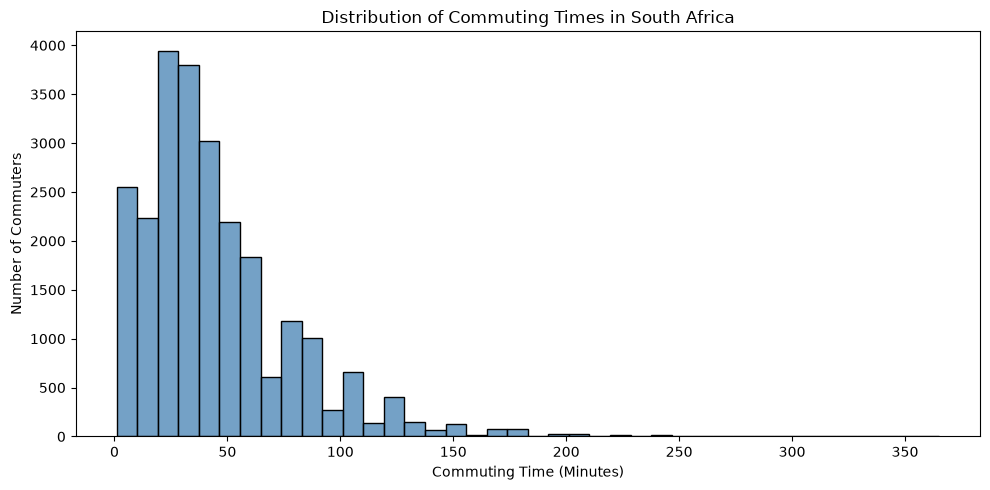

In [29]:
# Visualizing the distribution of commuting times
plt.figure(figsize=(10, 5))

sns.histplot(
    data=commute_df,
    x="Tot_time_travel_work",
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Commuting Times in South Africa")
plt.xlabel("Commuting Time (Minutes)")
plt.ylabel("Number of Commuters")

plt.tight_layout()
plt.show()

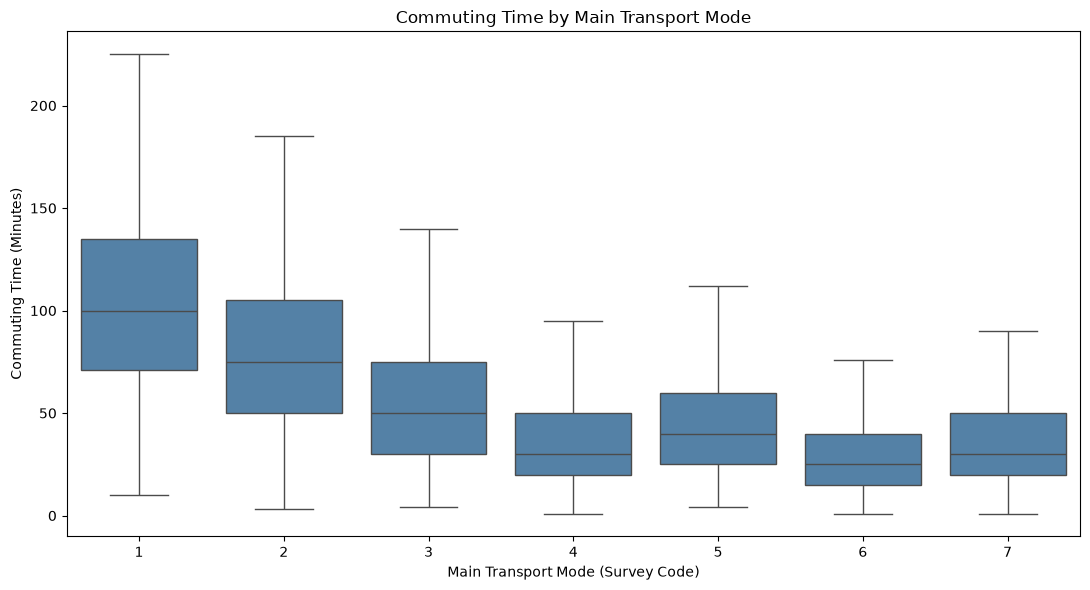

In [30]:
# Comparing commuting times across different transport modes
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=commute_df,
    x="Mainmode_work",
    y="Tot_time_travel_work",
    color="steelblue",
    showfliers=False
)

plt.title("Commuting Time by Main Transport Mode")
plt.xlabel("Main Transport Mode (Survey Code)")
plt.ylabel("Commuting Time (Minutes)")

plt.tight_layout()
plt.show()

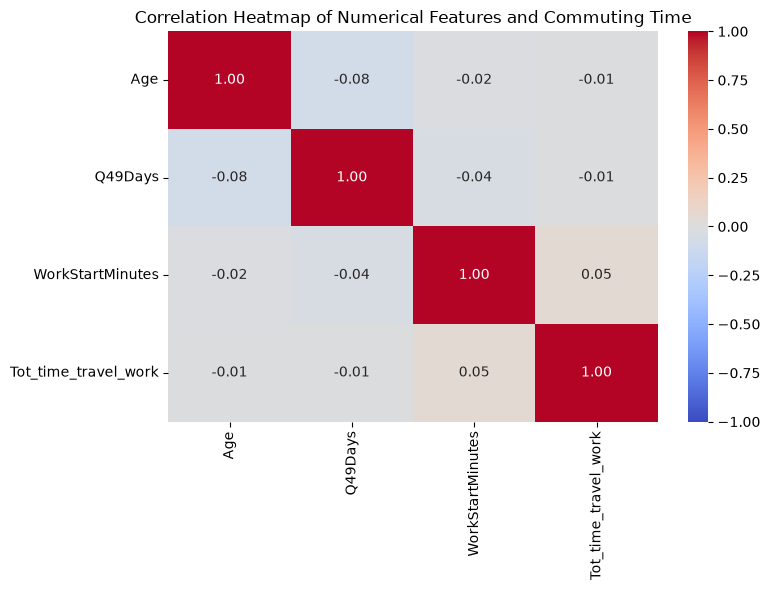

In [31]:
# Selecting numerical features and the target for correlation analysis
correlation_columns = numerical_features + [target]

# Calculating Pearson correlation coefficients
correlation_matrix = commute_df[correlation_columns].corr()

# Visualizing the correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features and Commuting Time")
plt.tight_layout()
plt.show()

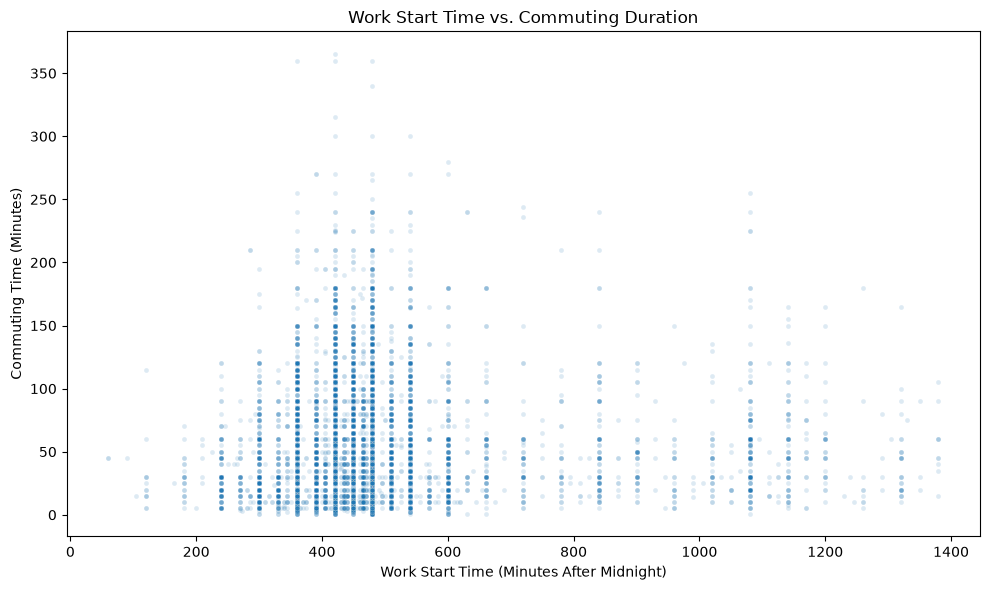

In [32]:
# Exploring the relationship between work start time and commuting duration
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=commute_df,
    x="WorkStartMinutes",
    y="Tot_time_travel_work",
    alpha=0.15,
    s=12
)

plt.title("Work Start Time vs. Commuting Duration")
plt.xlabel("Work Start Time (Minutes After Midnight)")
plt.ylabel("Commuting Time (Minutes)")

plt.tight_layout()
plt.show()

In [33]:
# Comparing commuting times across categorical features
for feature in categorical_features:
    summary = commute_df.groupby(feature)[target].agg(
        Count="count",
        Median="median",
        Mean="mean"
    )

    print(f"\n{feature}")
    print(summary.round(2))


Sex
     Count  Median   Mean
Sex                      
1    13122    39.5  45.76
2    11370    35.0  44.03

Q43SectOfWork
               Count  Median   Mean
Q43SectOfWork                      
1              15676    40.0  45.91
2               5738    30.0  42.53
3               3078    30.0  44.66

Q48bDMunic
            Count  Median   Mean
Q48bDMunic                      
11            696    50.0  60.47
12            270    25.0  32.53
13            937    25.0  29.81
14            359    20.0  27.19
15            702    30.0  33.44
16            348    15.0  21.33
18            463    25.0  31.25
19            293    30.0  32.80
20            279    30.0  34.09
21            185    20.0  35.08
22            247    35.0  43.73
23            300    30.0  36.18
24            425    40.0  43.41
25            424    35.0  42.48
27            278    30.0  40.55
28            165    20.0  25.27
29            127    20.0  23.14
30            329    25.0  33.46
31            162    30.

In [34]:
# Checking whether municipality codes fall within the expected valid range
print("Minimum municipality code:", commute_df["Q48bDMunic"].min())
print("Maximum municipality code:", commute_df["Q48bDMunic"].max())

# Counting records with municipality codes outside the accepted range
print(
    "Invalid municipality records:",
    (~commute_df["Q48bDMunic"].between(11, 70)).sum()
)

Minimum municipality code: 11
Maximum municipality code: 70
Invalid municipality records: 0


In [35]:
from sklearn.model_selection import train_test_split

# Separating independent variables (X) and the target (y)
X = commute_df[model_features]
y = commute_df[target]

# Splitting the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Checking the size of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (19593, 8)
Testing features: (4899, 8)
Training targets: (19593,)
Testing targets: (4899,)


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Defining transformations for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'Q49Days', 'WorkStartMinutes']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Sex', 'Q43SectOfWork', 'Q48bDMunic',
                                  'Q413EmployCash', 'Mainmode_work'])])
